# Phase 3: Exploratory Data Analysis
Brainpals asked for a look at what drives retail sales across its stores. This notebook explores `cleaned_master.csv` (46,800 rows: 30 stores x 15 products x 104 weeks) with eight figures. Every figure is saved to `figures/` at 300 dpi.

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)

df = pd.read_csv('cleaned_master.csv')
df['week_start'] = pd.to_datetime(df['week_start'])

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")

Loaded 46,800 rows and 47 columns.


## Figure 1: Weekly revenue, 12-week rolling mean and decomposition
Revenue is added up across all stores for each week. The decomposition splits it into **trend** (long-run direction), **seasonality** (a pattern that repeats every 52 weeks) and **residual** (what is left).

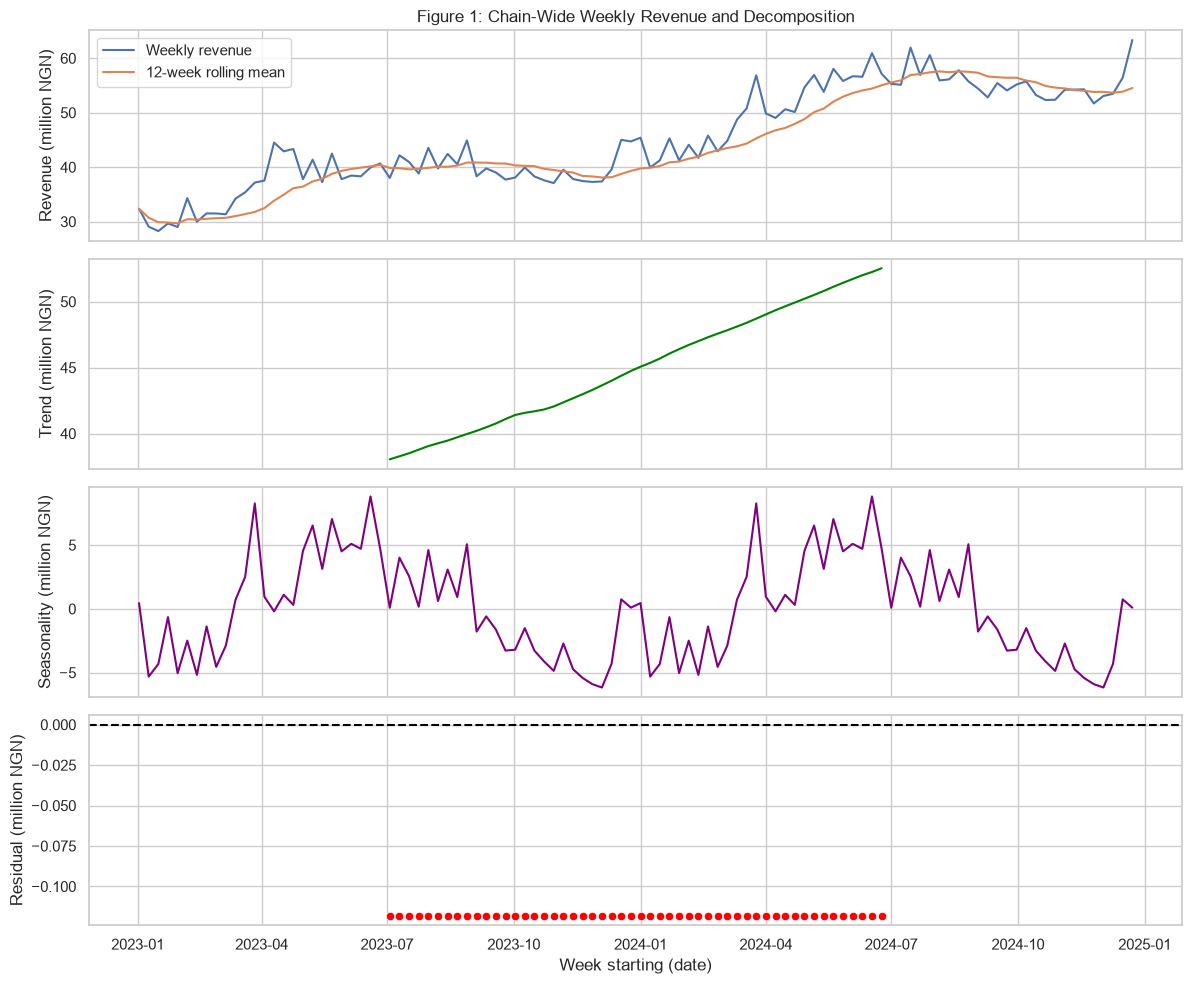

In [3]:
weekly = df.groupby('week_start')['revenue_ngn'].sum().reset_index()
weekly['revenue_m'] = weekly['revenue_ngn'] / 1e6
weekly['rolling_12'] = weekly['revenue_m'].rolling(12, min_periods=1).mean()

parts = seasonal_decompose(weekly.set_index('week_start')['revenue_m'], model='additive', period=52)
weekly['trend'] = parts.trend.values
weekly['seasonal'] = parts.seasonal.values
weekly['residual'] = parts.resid.values

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

sns.lineplot(data=weekly, x='week_start', y='revenue_m', label='Weekly revenue', ax=axes[0])
sns.lineplot(data=weekly, x='week_start', y='rolling_12', label='12-week rolling mean', ax=axes[0])
axes[0].set(title='Figure 1: Chain-Wide Weekly Revenue and Decomposition', ylabel='Revenue (million NGN)')

sns.lineplot(data=weekly, x='week_start', y='trend', ax=axes[1], color='green')
axes[1].set(ylabel='Trend (million NGN)')

sns.lineplot(data=weekly, x='week_start', y='seasonal', ax=axes[2], color='purple')
axes[2].set(ylabel='Seasonality (million NGN)')

sns.scatterplot(data=weekly, x='week_start', y='residual', ax=axes[3], color='red')
axes[3].axhline(0, color='black', linestyle='--')
axes[3].set(ylabel='Residual (million NGN)', xlabel='Week starting (date)')

plt.tight_layout()
plt.savefig('figures/fig1_revenue_ts.png', dpi=300)
plt.show()

**What it shows:** revenue roughly doubles over two years, but much of that is inflation (analysed in Question 4). The seasonal swing is small compared with the trend.

## Figure 2: Correlation heatmap of store and external variables
Each cell is the Pearson correlation (-1 to +1) between two numeric store or external variables. Store variables are repeated on every row for that store, so these correlations are weighted by rows.

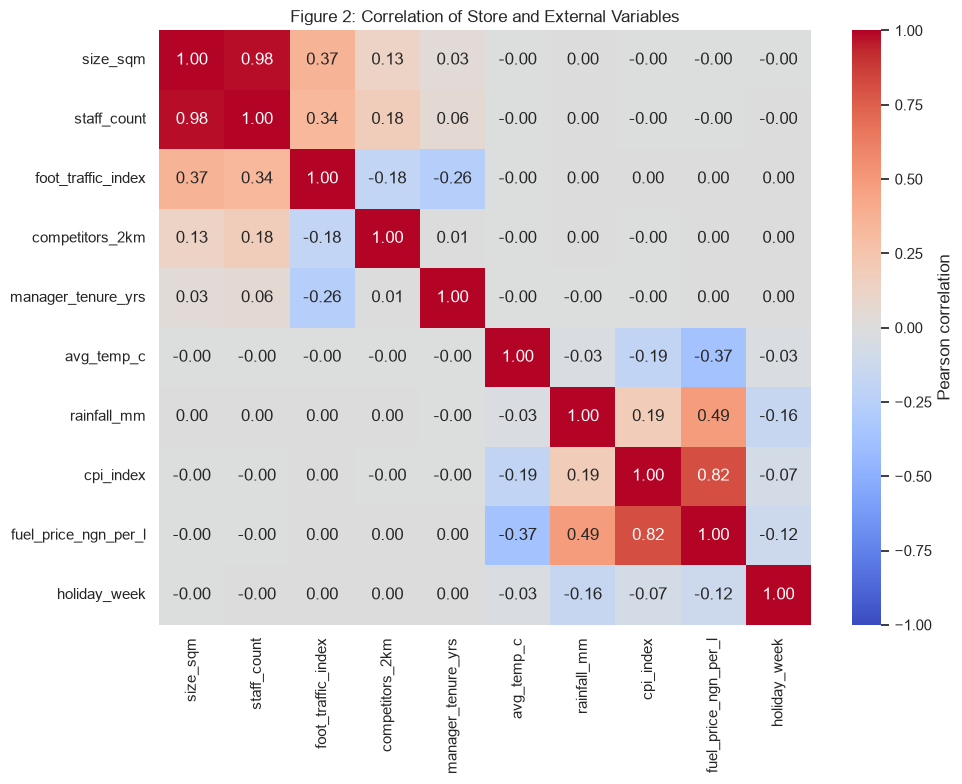

In [4]:
store_external_vars = [
    'size_sqm', 'staff_count', 'foot_traffic_index', 'competitors_2km', 'manager_tenure_yrs',
    'avg_temp_c', 'rainfall_mm', 'cpi_index', 'fuel_price_ngn_per_l', 'holiday_week'
]

plt.figure(figsize=(10, 8))
sns.heatmap(df[store_external_vars].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, cbar_kws={'label': 'Pearson correlation'})
plt.title('Figure 2: Correlation of Store and External Variables')
plt.tight_layout()
plt.savefig('figures/fig2_correlation_heatmap.png', dpi=300)
plt.show()

**What it shows:** `size_sqm` and `staff_count` are almost perfectly linked (bigger stores have more staff). This is the multicollinearity problem we deal with in the models. `cpi_index` and `fuel_price_ngn_per_l` also rise together over time.

## Figure 3: Promo vs non-promo units by category

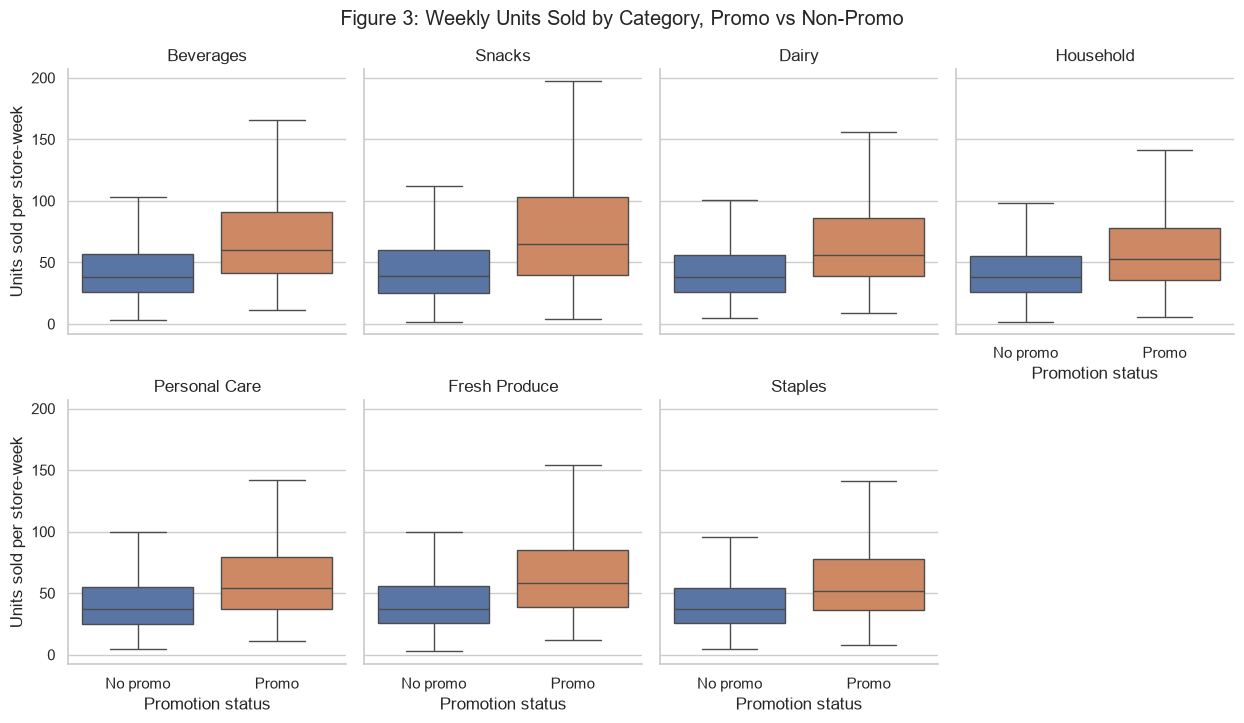

In [5]:
df['promo_label'] = df['promo_flag'].map({0: 'No promo', 1: 'Promo'})

g = sns.catplot(data=df, x='promo_label', y='units_sold', hue='promo_label', col='category',
                col_wrap=4, kind='box', showfliers=False, height=3.5, aspect=0.9, legend=False)
g.set_axis_labels('Promotion status', 'Units sold per store-week')
g.set_titles('{col_name}')
g.figure.suptitle('Figure 3: Weekly Units Sold by Category, Promo vs Non-Promo', y=1.03)
g.savefig('figures/fig3_promo_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

**What it shows:** the middle line (median) is higher for promotion weeks in every category.

## Figure 4: Store ranking by revenue per sqm vs revenue per staff member

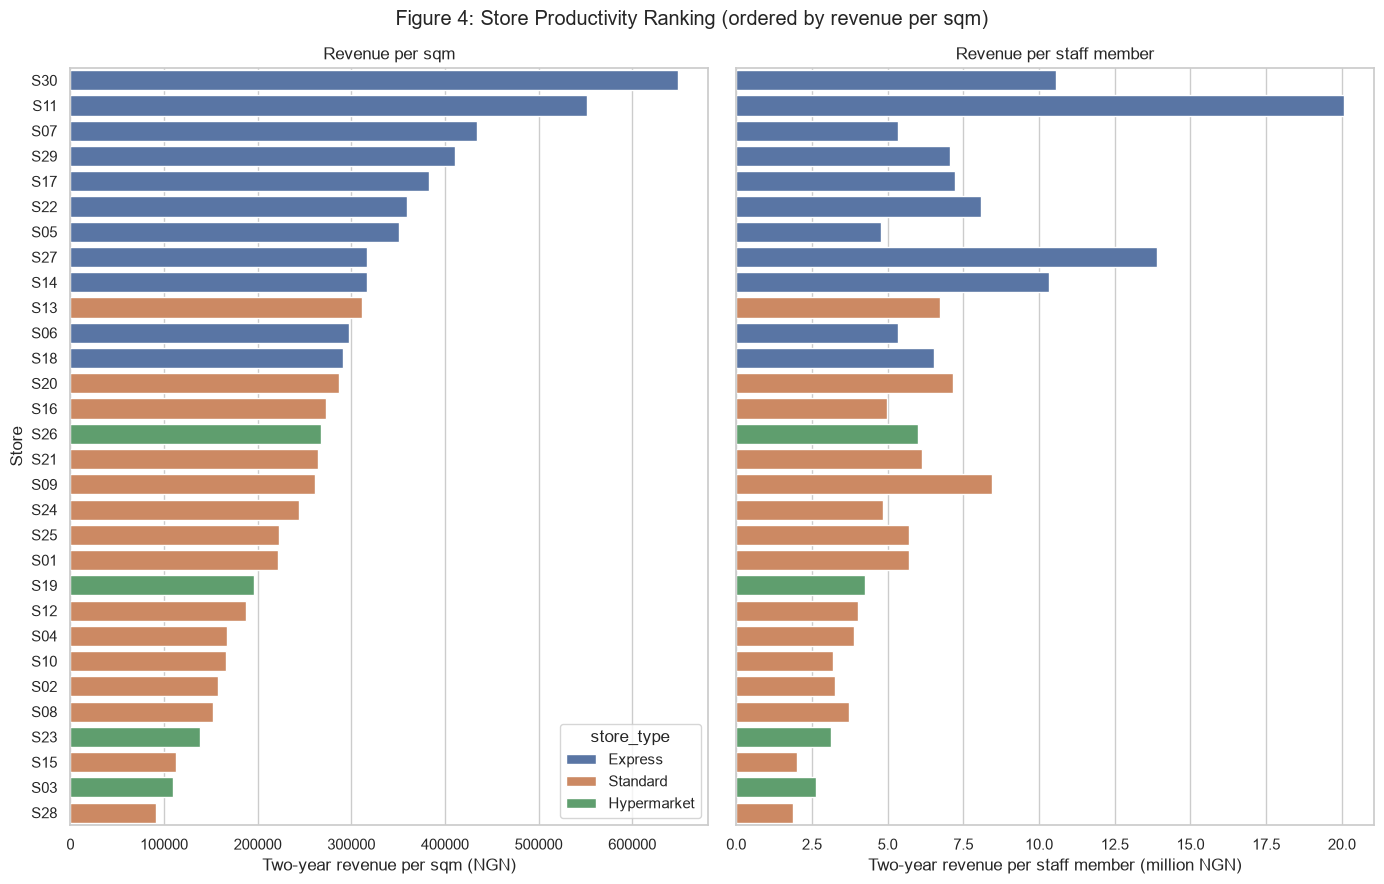

Rank correlation between the two measures: 0.83


In [6]:
stores = df.groupby(['store_id', 'store_type', 'size_sqm', 'staff_count'])['revenue_ngn'].sum().reset_index()
stores['revenue_per_sqm'] = stores['revenue_ngn'] / stores['size_sqm']
stores['revenue_per_staff_m'] = stores['revenue_ngn'] / stores['staff_count'] / 1e6
stores = stores.sort_values('revenue_per_sqm', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharey=True)

sns.barplot(data=stores, y='store_id', x='revenue_per_sqm', hue='store_type', dodge=False, ax=axes[0])
axes[0].set(title='Revenue per sqm', xlabel='Two-year revenue per sqm (NGN)', ylabel='Store')

sns.barplot(data=stores, y='store_id', x='revenue_per_staff_m', hue='store_type', dodge=False, ax=axes[1])
axes[1].set(title='Revenue per staff member', xlabel='Two-year revenue per staff member (million NGN)', ylabel='')
axes[1].get_legend().remove()

plt.suptitle('Figure 4: Store Productivity Ranking (ordered by revenue per sqm)')
plt.tight_layout()
plt.savefig('figures/fig4_store_productivity.png', dpi=300)
plt.show()

print('Rank correlation between the two measures:',
      round(stores['revenue_per_sqm'].corr(stores['revenue_per_staff_m'], method='spearman'), 2))

**What it shows:** Express stores take the top places on both measures (about 0.40 million NGN per sqm and 9 million per staff member on average), Standard stores sit in the middle, and Hypermarkets are lowest on both (about 0.18 million per sqm and 4 million per staff member). Hypermarkets bring in the most total revenue, but their large floor space and staff numbers dilute productivity. The two rankings broadly agree, so store format is the main driver of productivity.

## Figure 5: log price ratio vs log units, one panel per category
The slope of each line is that category's price elasticity (see Model A).

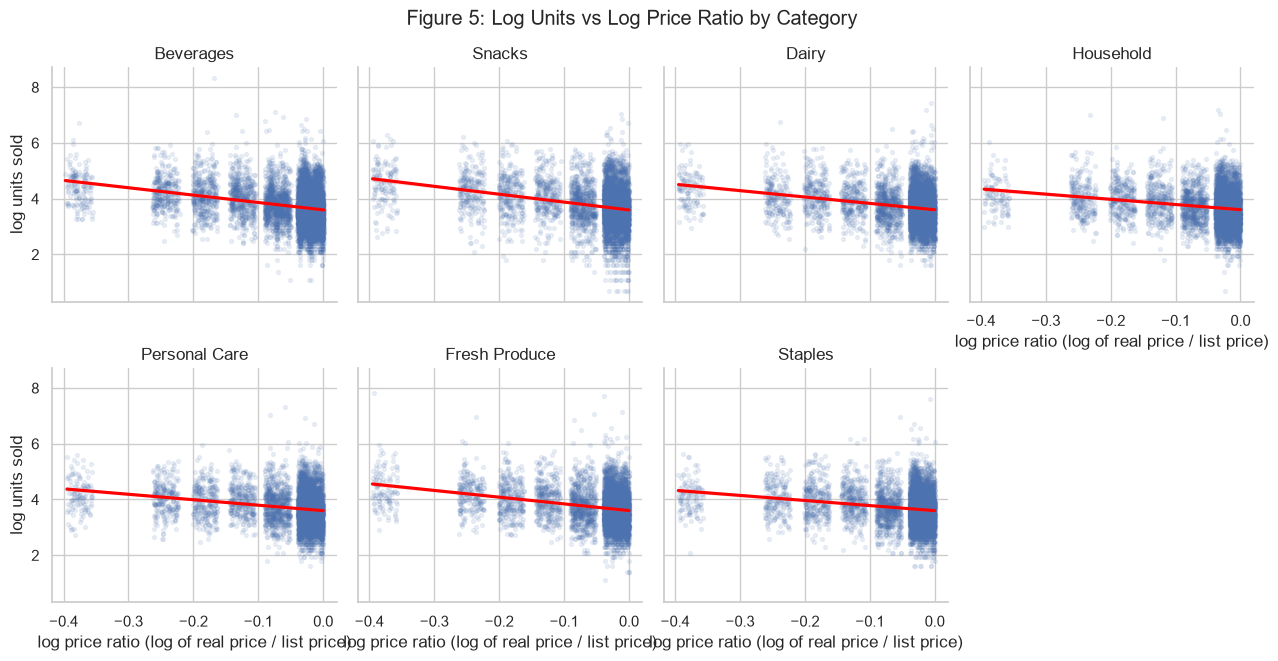

In [7]:
g = sns.lmplot(data=df, x='log_price_ratio', y='log_units', col='category', col_wrap=4,
               height=3.2, scatter_kws={'alpha': 0.1, 's': 8}, line_kws={'color': 'red'})
g.set_axis_labels('log price ratio (log of real price / list price)', 'log units sold')
g.set_titles('{col_name}')
g.figure.suptitle('Figure 5: Log Units vs Log Price Ratio by Category', y=1.03)
g.savefig('figures/fig5_log_price_vs_log_units.png', dpi=300, bbox_inches='tight')
plt.show()

**What it shows:** every line slopes downward. Lower real prices go with higher sales. The cloud is wide because other factors (promotions, store size, season) also matter.

## Figure 6: Units sold by store type
Left: boxplot (the middle 50% of values). Right: violin plot on a log scale, to show the long upper tail.

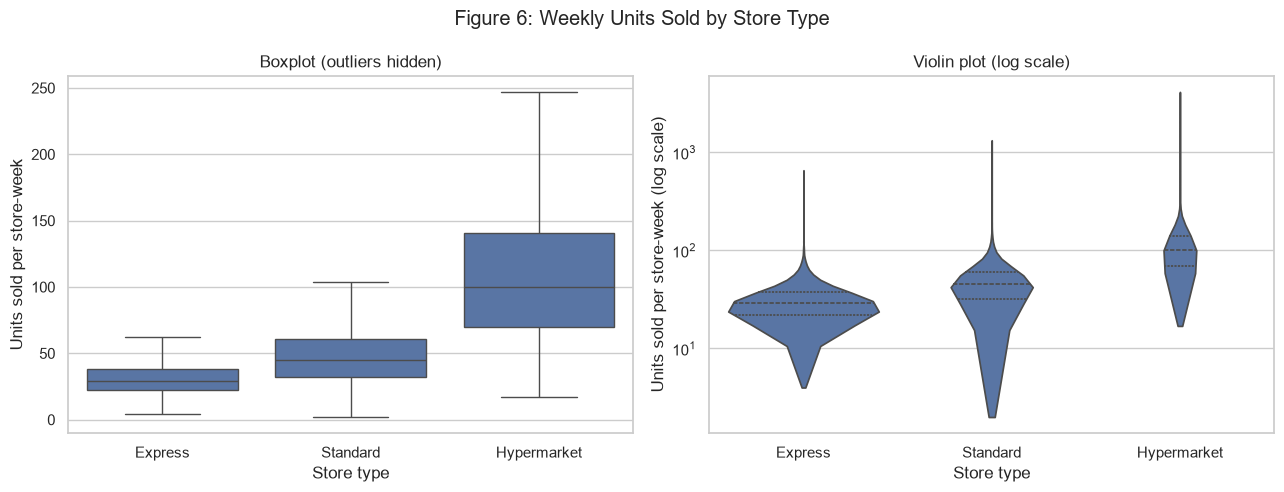

In [8]:
order = ['Express', 'Standard', 'Hypermarket']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='store_type', y='units_sold', order=order, showfliers=False, ax=axes[0])
axes[0].set(title='Boxplot (outliers hidden)', xlabel='Store type', ylabel='Units sold per store-week')

sns.violinplot(data=df, x='store_type', y='units_sold', order=order, cut=0, inner='quartile', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set(title='Violin plot (log scale)', xlabel='Store type', ylabel='Units sold per store-week (log scale)')

plt.suptitle('Figure 6: Weekly Units Sold by Store Type')
plt.tight_layout()
plt.savefig('figures/fig6_units_by_store_type.png', dpi=300)
plt.show()

**What it shows:** Hypermarkets sell the most units per week and Express stores the fewest. All three formats have a long tail of very large weeks.

## Figure 7: Pearson vs Spearman correlation
Pearson measures straight-line relationships. Spearman works on ranks, so it picks up any steadily rising or falling relationship, even a curved one. Where the two disagree, the relationship is not a straight line, or a few extreme values are distorting it.

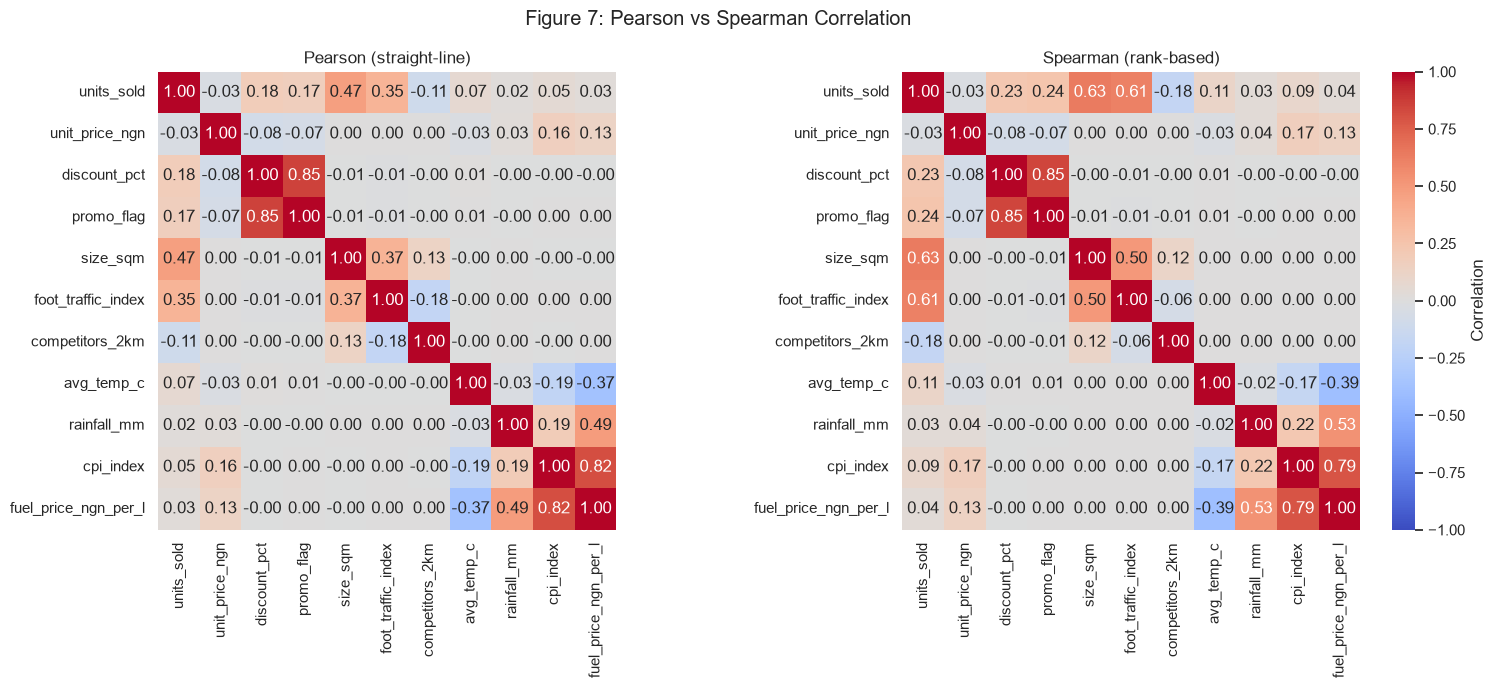

In [9]:
corr_vars = [
    'units_sold', 'unit_price_ngn', 'discount_pct', 'promo_flag', 'size_sqm', 'foot_traffic_index',
    'competitors_2km', 'avg_temp_c', 'rainfall_mm', 'cpi_index', 'fuel_price_ngn_per_l'
]

pearson = df[corr_vars].corr(method='pearson')
spearman = df[corr_vars].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.heatmap(pearson, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0,
            cbar=False, square=True, ax=axes[0])
axes[0].set_title('Pearson (straight-line)')
sns.heatmap(spearman, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, cbar_kws={'label': 'Correlation'}, ax=axes[1])
axes[1].set_title('Spearman (rank-based)')
plt.suptitle('Figure 7: Pearson vs Spearman Correlation')
plt.tight_layout()
plt.savefig('figures/fig7_pearson_vs_spearman.png', dpi=300)
plt.show()

In [10]:
# Table of the pairs where the two methods disagree most
table = pd.DataFrame({'pearson': pearson.unstack(), 'spearman': spearman.unstack()}).reset_index()
table.columns = ['variable_1', 'variable_2', 'pearson', 'spearman']
table['gap'] = (table['pearson'] - table['spearman']).abs()
table = table[table['variable_1'] < table['variable_2']]
table.sort_values('gap', ascending=False).head(8).round(2).reset_index(drop=True)

,variable_1,variable_2,pearson,spearman,gap
0,foot_traffic_index,units_sold,0.35,0.61,0.26
1,size_sqm,units_sold,0.47,0.63,0.16
2,foot_traffic_index,size_sqm,0.37,0.50,0.13
3,competitors_2km,foot_traffic_index,-0.18,-0.06,0.12
4,promo_flag,units_sold,0.17,0.24,0.07
5,competitors_2km,units_sold,-0.11,-0.18,0.07
6,discount_pct,units_sold,0.18,0.23,0.05
7,avg_temp_c,units_sold,0.07,0.11,0.04


**Where they disagree:** the biggest gaps involve `units_sold`. For `foot_traffic_index` vs `units_sold`, Pearson is 0.35 but Spearman is 0.61. Sales are very skewed (a few huge weeks), and those extremes weaken the straight-line measure, while the rank measure shows that busier stores consistently sell more. The same happens for `size_sqm` vs `units_sold` (0.47 vs 0.63). The practical lesson is that sales respond to store size and traffic in a curved, not straight-line, way, which is why we model `log_units`.

## Figure 8: Customer spend vs visits, coloured by loyalty tier

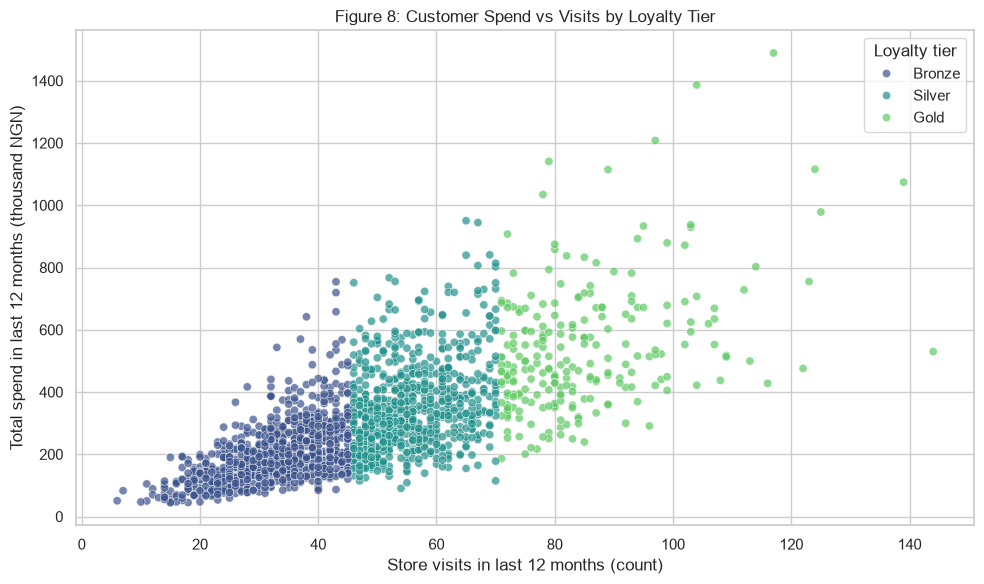

In [11]:
customers = pd.read_excel('Brainpals_sales_analytics.xlsx', sheet_name='Customers')
customers['spend_k_ngn'] = customers['total_spend_12m_ngn'] / 1e3

plt.figure(figsize=(10, 6))
sns.scatterplot(data=customers, x='visits_12m', y='spend_k_ngn', hue='loyalty_tier',
                hue_order=['Bronze', 'Silver', 'Gold'], palette='viridis', alpha=0.7)
plt.title('Figure 8: Customer Spend vs Visits by Loyalty Tier')
plt.xlabel('Store visits in last 12 months (count)')
plt.ylabel('Total spend in last 12 months (thousand NGN)')
plt.legend(title='Loyalty tier')
plt.tight_layout()
plt.savefig('figures/fig8_customer_spend_vs_visits.png', dpi=300)
plt.show()

**What it shows:** spend rises with visits. Gold customers sit towards the high-visit, high-spend side, and Bronze customers are spread across lower values.